In [1]:
import zhinst.core as zi
import numpy as np
import time
import matplotlib.pyplot as plt

In [70]:
# ── 1. Connect ─────────────────────────────────────────────────────────────────
daq = zi.ziDAQServer('localhost', 8004, 6)
daq.connectDevice('DEV2772', '1GbE')
device = 'DEV2772'

In [71]:

# ── 2. Parameters ──────────────────────────────────────────────────────────────
demod_rate  = 0.5e6    # Sa/s — max UHFLI demodulator output rate
duration    = 45e-6    # s    — DAQ capture window per trigger
n_triggers  = 10       # number of pulses to capture per acquisition

# Grid: number of output samples per capture window
n_cols = int(np.ceil(duration * demod_rate))  # = 54 samples at 1.8 MSa/s
print(f"Grid: {n_cols} samples per {duration*1e6:.0f} µs window "
      f"({demod_rate/1e6:.1f} MSa/s)")

# ── 3. Configure demodulator 0 at maximum rate ─────────────────────────────────
# The demodulator sample bundles Aux In 1 (auxin0) at the demod output rate
daq.set([
    (f'/{device}/oscs/0/freq',               1e3),    # low osc freq (quasi-DC)
    (f'/{device}/demods/0/oscselect',         0),
    (f'/{device}/demods/0/adcselect',         0),      # Signal Input 1
    (f'/{device}/demods/0/order',             1),      # 1st order filter → fastest response
    (f'/{device}/demods/0/timeconstant',      1 / demod_rate),
    (f'/{device}/demods/0/rate',              demod_rate),
    (f'/{device}/demods/0/enable',            1),
])

# ── 4. Configure and run DAQ module ───────────────────────────────────────────
daqm = daq.dataAcquisitionModule()

daqm.set('device',            device)
daqm.set('type',              6)           # 6 = hardware digital trigger
daqm.set('triggernode',       f'/{device}/demods/0/sample.TrigIn3')
daqm.set('edge',              1)           # 1 = rising edge
#daqm.set('duration',          duration)
daqm.set('delay',             0.0)         # no pre-trigger delay
daqm.set('holdoff/time',      0.0)         # minimum holdoff
daqm.set('holdoff/count',     0)
daqm.set('count',             n_triggers)
daqm.set('endless',           0)           # finite acquisition
daqm.set('grid/mode',         4)           # 4 = Exact interpolation onto grid
daqm.set('grid/cols',         n_cols)
daqm.set('grid/rows',         n_triggers)
daqm.set('grid/repetitions',  1)

# Subscribe: demod sample includes auxin0 (= Aux In 1) at the demod rate
node_path = f'/{device}/demods/0/sample.AuxIn0.avg'


Grid: 23 samples per 45 µs window (0.5 MSa/s)


In [72]:

# ── 5. Acquire ────────────────────────────────────────────────────────────────
daqm.subscribe(node_path)
daqm.execute()
print(f"DAQ running — waiting for {n_triggers} triggers on TrigIn3...")

timeout = 10  # s — increase if pulse train is slow to arrive
t0 = time.time()
while not daqm.finished():
    if time.time() - t0 > timeout:
        print("⚠  Timeout — reading whatever was captured.")
        break
    #prog = daqm.getDouble('progress') * 100
    prog = daqm.progress()[0] * 100
    print(f"  Progress: {prog:.0f} %", end='\r')
    time.sleep(0.05)

data = daqm.read(True)    # True = flat (non-nested) format
daqm.finish()
daqm.unsubscribe('*')
print(f"\nAcquisition done.")

DAQ running — waiting for 10 triggers on TrigIn3...
⚠  Timeout — reading whatever was captured.

Acquisition done.


Available sample fields: ['header', 'timestamp', 'value']


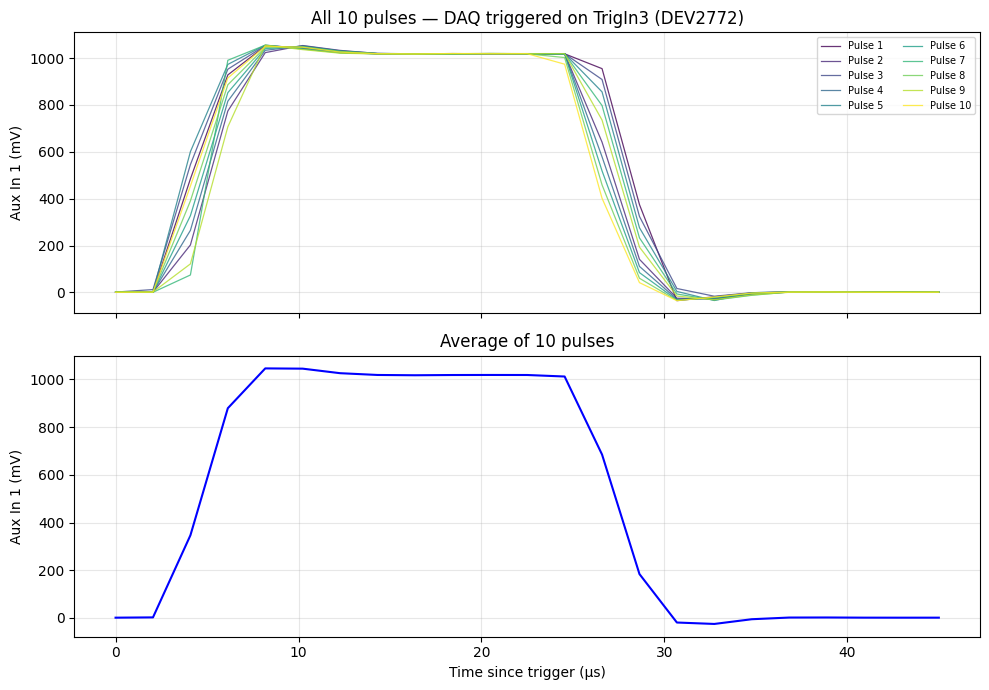

In [85]:

# ── 6. Extract Aux In 1 ────────────────────────────────────────────────────────
node_key = node_path.lower()
bursts   = data[node_key]          # list of captured segments

# Aux In 1 is 'auxin0' in the demod sample (0-indexed)
# Print available fields on first burst for reference:
print("Available sample fields:", list(bursts[0].keys()))

# Build 2D matrix: shape (n_triggers, n_cols)
aux_matrix = np.zeros((n_triggers, n_cols))
t_us       = np.linspace(0, duration * 1e6, n_cols)   # time axis in µs

#for i, burst in enumerate(bursts[:n_triggers]):
#    aux_matrix[i,:] = burst['value'][i][:]

# ── 7. Plot ───────────────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

cmap   = plt.cm.viridis
colors = [cmap(i / (n_triggers - 1)) for i in range(n_triggers)]

for i in range(n_triggers):
    ax1.plot(t_us, bursts[0]['value'][i]*1e3, lw=0.9,
             color=colors[i], alpha=0.8, label=f'Pulse {i+1}')
ax1.set_ylabel('Aux In 1 (mV)')
ax1.set_title(f'All {n_triggers} pulses — DAQ triggered on TrigIn3 (DEV2772)')
ax1.legend(fontsize=7, ncol=2, loc='upper right')
ax1.grid(True, alpha=0.3)

avg = bursts[0]['value'].mean(axis=0)
ax2.plot(t_us, avg * 1e3, 'b-', lw=1.5)
ax2.set_ylabel('Aux In 1 (mV)')
ax2.set_xlabel('Time since trigger (µs)')
ax2.set_title(f'Average of {n_triggers} pulses')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()